# Cats vs Dogs CNN (PyTorch)
Fixed version: cleans corrupt images *before* training, uses augmentation, validates every epoch, keeps the best model and saves it for the FastAPI app.

In [1]:
import os, random
import numpy as np
import torch, torch.nn as nn, torch.optim as optim
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from sklearn.metrics import classification_report, confusion_matrix

dataset_path = r"C:\Users\Buddhadev Mondal\Desktop\cats_dogs"   # cats_dogs folder present in desktop 
IMG_SIZE, BATCH_SIZE, EPOCHS, LR, SEED = 128, 64, 12, 1e-3, 42
MEAN, STD = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)
MODEL_FILE = "cats_dogs_cnn.pth"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print(os.listdir(dataset_path))
for c in ["cat", "dog"]:
    print(c, len(os.listdir(os.path.join(dataset_path, c))))

Using device: cpu
['Cat', 'Dog']
cat 12499
dog 12499


## 1. Remove corrupt images
The original notebook checked for bad images *after* training, so a single broken file could crash training. We now fully decode every image first and skip the bad ones.

In [2]:
bad_images = set()
for c in ["cat", "dog"]:
    folder = os.path.join(dataset_path, c)
    for name in os.listdir(folder):
        path = os.path.join(folder, name)
        try:
            with Image.open(path) as im:
                im.convert("RGB").load()      # full decode, stricter than verify()
        except Exception:
            bad_images.add(path)
print("Bad images:", len(bad_images))
for p in list(bad_images)[:10]: print(p)

C:\ProgramData\anaconda3\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Bad images: 0


## 2. Look at the data

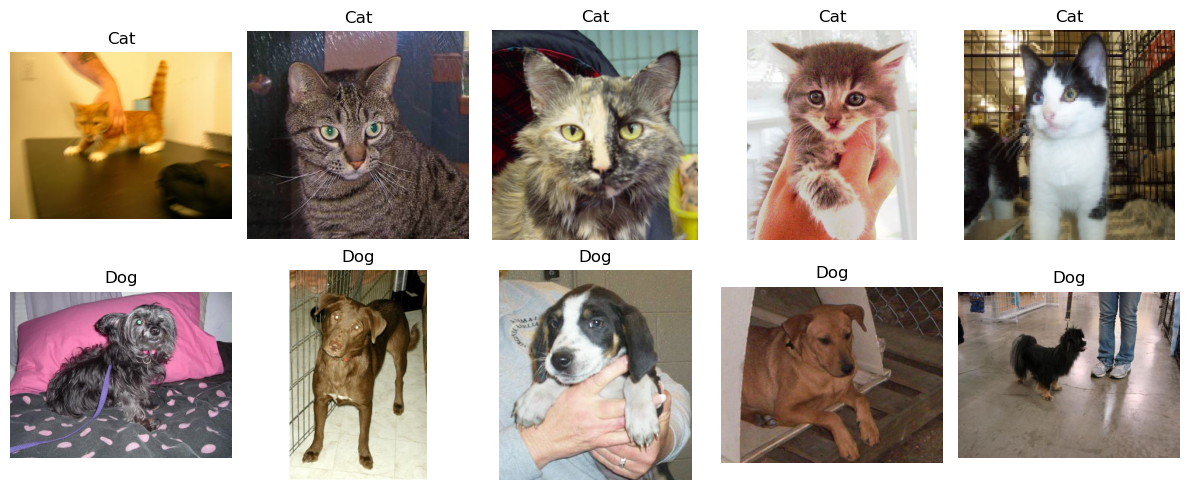

In [3]:
cat_dir, dog_dir = os.path.join(dataset_path, "cat"), os.path.join(dataset_path, "dog")
def sample(folder, n=5):
    good = [f for f in os.listdir(folder) if os.path.join(folder, f) not in bad_images]
    return [os.path.join(folder, f) for f in good[:n]]

plt.figure(figsize=(12, 5))
for i, p in enumerate(sample(cat_dir)):
    plt.subplot(2, 5, i + 1); plt.imshow(Image.open(p).convert("RGB")); plt.title("Cat"); plt.axis("off")
for i, p in enumerate(sample(dog_dir)):
    plt.subplot(2, 5, i + 6); plt.imshow(Image.open(p).convert("RGB")); plt.title("Dog"); plt.axis("off")
plt.tight_layout(); plt.show()

## 3. Transforms, clean split, loaders
Augmentation is applied to the training set only. The split is seeded so results are reproducible.

In [4]:
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_full = ImageFolder(dataset_path, transform=train_tf)
eval_full  = ImageFolder(dataset_path, transform=eval_tf)
print("Classes:", train_full.class_to_idx)          # {'cat': 0, 'dog': 1} -> sigmoid output = P(dog)

good_idx = [i for i, (p, _) in enumerate(train_full.samples) if p not in bad_images]
perm = torch.randperm(len(good_idx), generator=torch.Generator().manual_seed(SEED)).tolist()
cut = int(0.8 * len(good_idx))
train_idx = [good_idx[i] for i in perm[:cut]]
test_idx  = [good_idx[i] for i in perm[cut:]]

trainset, testset = Subset(train_full, train_idx), Subset(eval_full, test_idx)
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
testloader  = DataLoader(testset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Train:", len(trainset), "Test:", len(testset))

Classes: {'Cat': 0, 'Dog': 1}
Train: 19998 Test: 5000


## 4. Model
Same idea as before, plus BatchNorm and Dropout. **This class must stay identical to `model.py`** used by the API.

In [5]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o):
            return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2, 2)]
        self.conv_layers = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128))
        self.fc_layers = nn.Sequential(
            nn.Linear(16 * 16 * 128, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 1))
    def forward(self, x):
        x = self.conv_layers(x)
        return self.fc_layers(x.view(x.size(0), -1))

model = CNN().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

## 5. Train (validate every epoch, keep the best model)

In [6]:
import time
history = {"train_loss": [], "test_loss": [], "test_acc": []}
best_acc = 0.0

for epoch in range(EPOCHS):
    start = time.time()
    model.train(); running = 0.0
    for i, (images, labels) in enumerate(trainloader, 1):
        images, labels = images.to(device), labels.float().view(-1, 1).to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward(); optimizer.step()
        running += loss.item()
        if i % 50 == 0:
            print(f"  epoch {epoch+1} batch {i}/{len(trainloader)} | {time.time()-start:.0f}s", flush=True)

    model.eval(); t_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.float().view(-1, 1).to(device)
            out = model(images)
            t_loss += criterion(out, labels).item()
            correct += ((torch.sigmoid(out) > 0.5).float() == labels).sum().item()
            total += labels.size(0)

    history["train_loss"].append(running / len(trainloader))
    history["test_loss"].append(t_loss / len(testloader))
    acc = correct / total; history["test_acc"].append(acc)
    print(f"Epoch {epoch+1}/{EPOCHS} | train loss {history['train_loss'][-1]:.4f} | "
          f"test loss {history['test_loss'][-1]:.4f} | test acc {acc:.2%} | {time.time()-start:.0f}s")

    if acc > best_acc:
        best_acc = acc
        torch.save({"state_dict": model.state_dict(), "classes": list(train_full.class_to_idx.keys()),
                    "img_size": IMG_SIZE, "mean": MEAN, "std": STD}, MODEL_FILE)
        print(f"  saved best model -> {MODEL_FILE}")
print("Best test accuracy:", f"{best_acc:.2%}")

  epoch 1 batch 50/313 | 130s
  epoch 1 batch 100/313 | 246s
  epoch 1 batch 150/313 | 363s
  epoch 1 batch 200/313 | 480s
  epoch 1 batch 250/313 | 598s
  epoch 1 batch 300/313 | 718s
Epoch 1/12 | train loss 0.8360 | test loss 0.6176 | test acc 60.62% | 829s
  saved best model -> cats_dogs_cnn.pth
  epoch 2 batch 50/313 | 118s
  epoch 2 batch 100/313 | 236s
  epoch 2 batch 150/313 | 370s
  epoch 2 batch 200/313 | 536s
  epoch 2 batch 250/313 | 664s
  epoch 2 batch 300/313 | 786s
Epoch 2/12 | train loss 0.5905 | test loss 0.5636 | test acc 69.86% | 899s
  saved best model -> cats_dogs_cnn.pth
  epoch 3 batch 50/313 | 118s
  epoch 3 batch 100/313 | 240s
  epoch 3 batch 150/313 | 360s
  epoch 3 batch 200/313 | 478s
  epoch 3 batch 250/313 | 598s
  epoch 3 batch 300/313 | 718s
Epoch 3/12 | train loss 0.5471 | test loss 0.4972 | test acc 74.60% | 830s
  saved best model -> cats_dogs_cnn.pth
  epoch 4 batch 50/313 | 129s
  epoch 4 batch 100/313 | 254s
  epoch 4 batch 150/313 | 375s
  epoch 

## 6. Evaluate the saved (best) model

              precision    recall  f1-score   support

         Cat       0.84      0.90      0.87      2504
         Dog       0.89      0.82      0.86      2496

    accuracy                           0.86      5000
   macro avg       0.86      0.86      0.86      5000
weighted avg       0.86      0.86      0.86      5000

Confusion matrix:
 [[2251  253]
 [ 441 2055]]


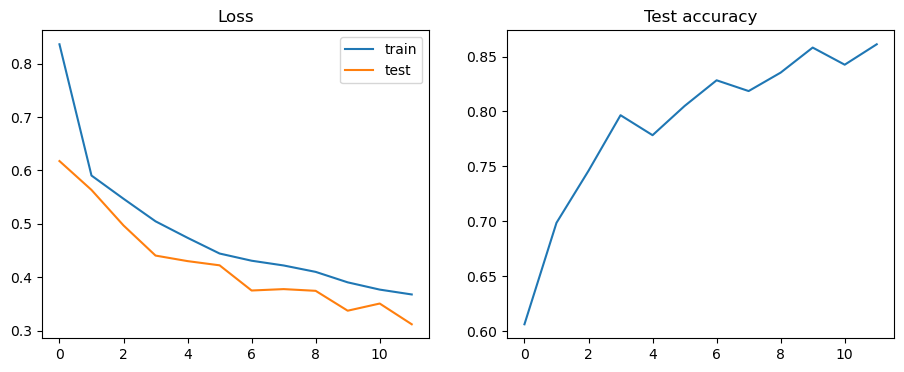

In [10]:
ckpt = torch.load(MODEL_FILE, map_location=device)
model.load_state_dict(ckpt["state_dict"]); model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in testloader:
        pred = (torch.sigmoid(model(images.to(device))) > 0.5).int().view(-1).cpu()
        y_true += labels.tolist(); y_pred += pred.tolist()
print(classification_report(y_true, y_pred, target_names=ckpt["classes"]))
print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["test_loss"], label="test"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["test_acc"]); ax[1].set_title("Test accuracy")
plt.show()

## 7. Try one image
Replace the path with any cat or dog photo.

In [11]:
def predict_image(path):
    img = Image.open(path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        p_dog = torch.sigmoid(model(x)).item()
    label = "dog" if p_dog > 0.5 else "cat"
    print(f"{label}  (dog probability {p_dog:.2%})")

predict_image(sample(cat_dir, 1)[0])
predict_image(sample(dog_dir, 1)[0])

cat  (dog probability 11.95%)
dog  (dog probability 98.72%)
